# 01 Exploratory data analysis

Alzheimer's Disease Dataset (Rabie El Kharoua, 2024, CC BY 4.0). **The data are synthetic**, generated
by the author for educational purposes, so findings here describe the generator, not real patients.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from common import (BINARY, CONTINUOUS, FIGURES_DIR, NOMINAL, RESULTS_DIR, load_test, load_train)

sns.set_theme(style="whitegrid")
X, y = load_train()
_, X_test = load_test()
print("train:", X.shape, "| test:", X_test.shape)
print("missing values:", int(X.isna().sum().sum() + X_test.isna().sum().sum()))
print(y.value_counts().rename({0: "no AD (0)", 1: "AD (1)"}).to_string())
print(f"AD share: {y.mean():.3f}")

train: (1504, 32) | test: (645, 32)
missing values: 0
Diagnosis
no AD (0)    972
AD (1)       532
AD share: 0.354


## Categorical features

2 nominal features (one-hot encoded later) and 15 binary features.

In [2]:
pd.DataFrame({c: X[c].value_counts().sort_index() for c in NOMINAL + BINARY}).T.fillna(0).astype(int)

,0,1,2,3
Ethnicity,890,309,154,151
EducationLevel,311,588,454,151
Gender,739,765,0,0
Smoking,1077,427,0,0
FamilyHistoryAlzheimers,1136,368,0,0
CardiovascularDisease,1302,202,0,0
Diabetes,1264,240,0,0
Depression,1191,313,0,0
HeadInjury,1361,143,0,0
Hypertension,1276,228,0,0


## Continuous features

In [3]:
X[CONTINUOUS].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Age,1504.0,74.9,9.0,60.0,67.0,75.0,83.0,90.0
BMI,1504.0,27.5,7.2,15.0,21.4,27.8,33.8,39.9
AlcoholConsumption,1504.0,10.0,5.7,0.0,5.2,9.9,15.1,20.0
PhysicalActivity,1504.0,4.9,2.9,0.0,2.5,4.8,7.5,10.0
DietQuality,1504.0,4.9,2.9,0.0,2.3,5.0,7.6,10.0
SleepQuality,1504.0,7.0,1.8,4.0,5.5,7.1,8.6,10.0
SystolicBP,1504.0,134.7,25.8,90.0,112.0,135.0,156.0,179.0
DiastolicBP,1504.0,89.7,17.7,60.0,74.0,90.0,105.0,119.0
CholesterolTotal,1504.0,225.2,42.3,150.1,190.5,224.4,262.5,300.0
CholesterolLDL,1504.0,124.9,43.5,50.4,87.5,124.5,162.0,200.0


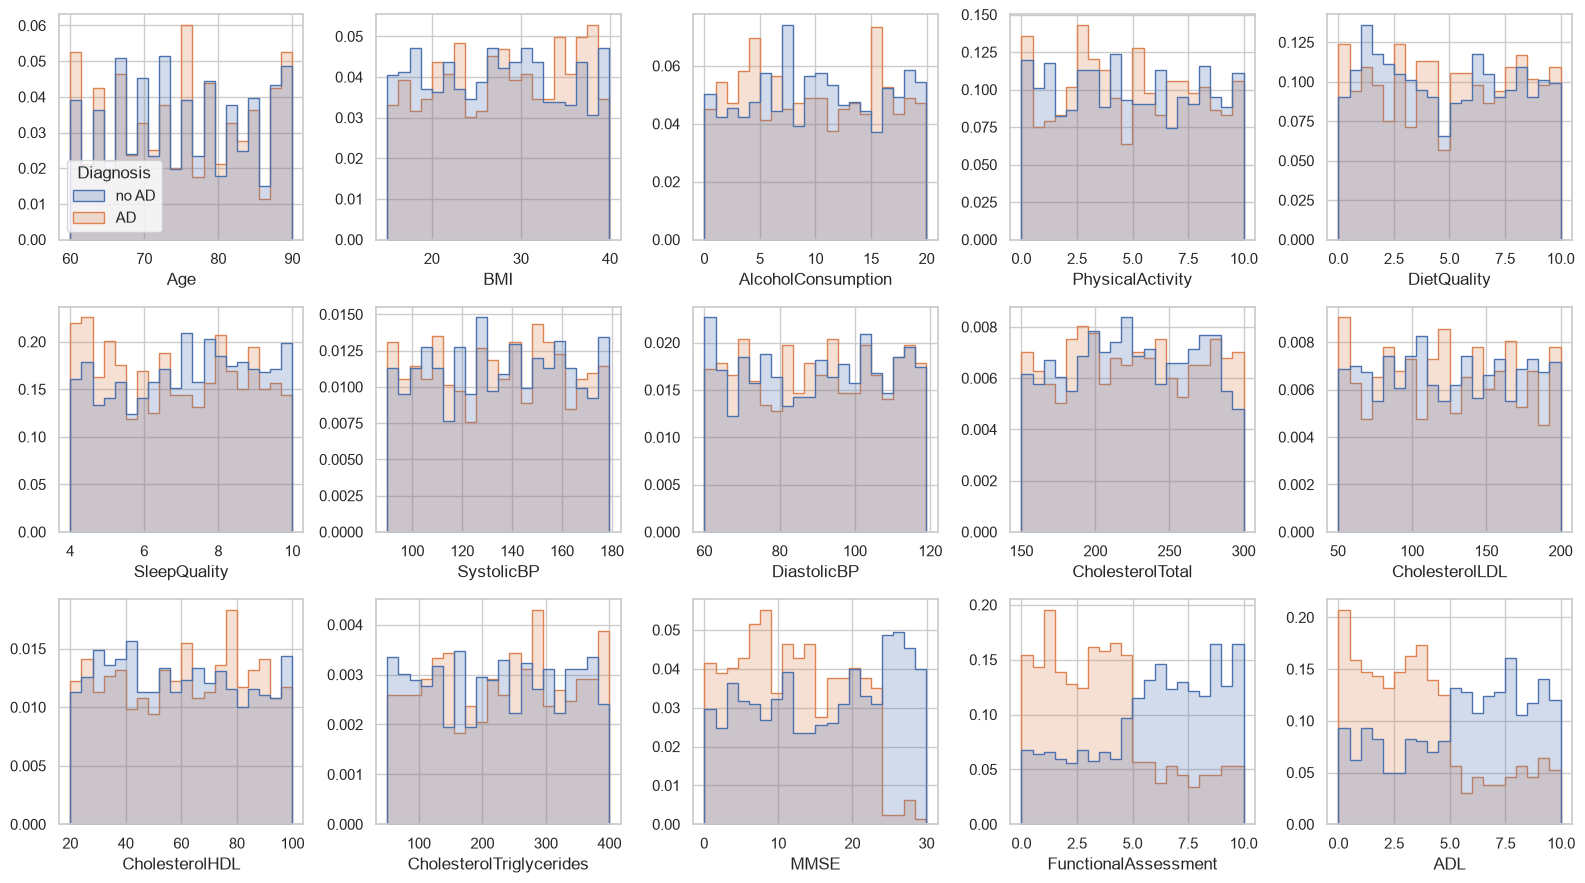

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for ax, col in zip(axes.flat, CONTINUOUS):
    sns.histplot(x=X[col], hue=y.map({0: "no AD", 1: "AD"}), bins=20, stat="density",
                 common_norm=False, element="step", ax=ax, legend=(col == CONTINUOUS[0]))
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_continuous.png", dpi=150)
plt.show()

## Correlation between features

The 2024 report attributed logistic regression's weakness to multicollinearity among
MemoryComplaints, DifficultyCompletingTasks and Forgetfulness. Check it directly.

largest |correlation| between two features: 0.082 ('BMI', 'CholesterolHDL')
                           MemoryComplaints  DifficultyCompletingTasks  \
MemoryComplaints                      1.000                      0.062   
DifficultyCompletingTasks             0.062                      1.000   
Forgetfulness                        -0.002                     -0.009   

                           Forgetfulness  
MemoryComplaints                  -0.002  
DifficultyCompletingTasks         -0.009  
Forgetfulness                      1.000  


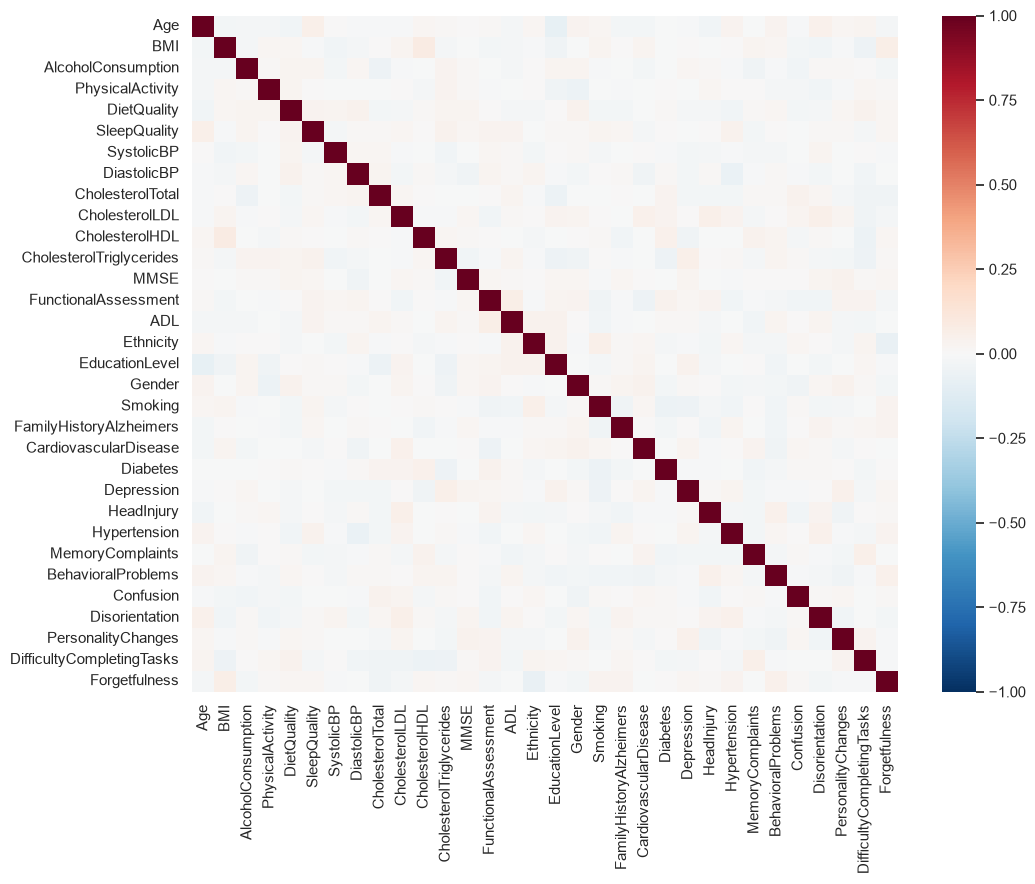

In [5]:
corr = X.corr()
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).abs()
pair = off_diag.stack().idxmax()
print(f"largest |correlation| between two features: {off_diag.max().max():.3f} {pair}")
print(corr.loc[["MemoryComplaints", "DifficultyCompletingTasks", "Forgetfulness"],
               ["MemoryComplaints", "DifficultyCompletingTasks", "Forgetfulness"]].round(3))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_feature_correlation.png", dpi=150)
plt.show()

## Association with the diagnosis

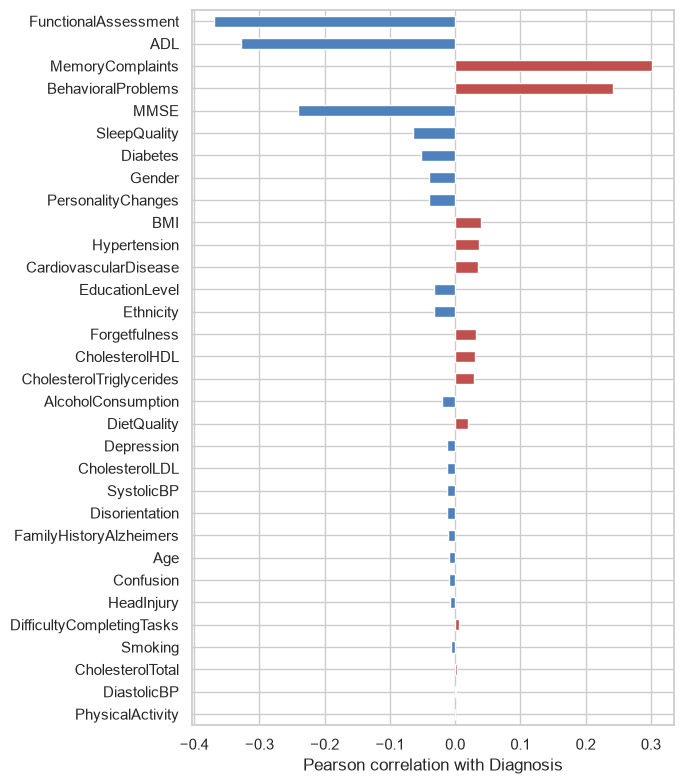

FunctionalAssessment   -0.369
ADL                    -0.328
MemoryComplaints        0.302
BehavioralProblems      0.242
MMSE                   -0.241
SleepQuality           -0.065
Diabetes               -0.053
Gender                 -0.041
Name: corr_with_diagnosis, dtype: float64

In [6]:
assoc = X.corrwith(y).sort_values(key=np.abs, ascending=False).rename("corr_with_diagnosis")
assoc.to_csv(RESULTS_DIR / "eda_target_correlation.csv")

fig, ax = plt.subplots(figsize=(7, 8))
assoc.iloc[::-1].plot.barh(ax=ax, color=np.where(assoc.iloc[::-1] > 0, "#c0504d", "#4f81bd"))
ax.set_xlabel("Pearson correlation with Diagnosis")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_target_correlation.png", dpi=150)
plt.show()
assoc.head(8).round(3)

## Shape of the effect

AD rate by decile of the three strongest continuous features. A step-like curve is something a
linear-in-features logistic model cannot represent, but a tree can.

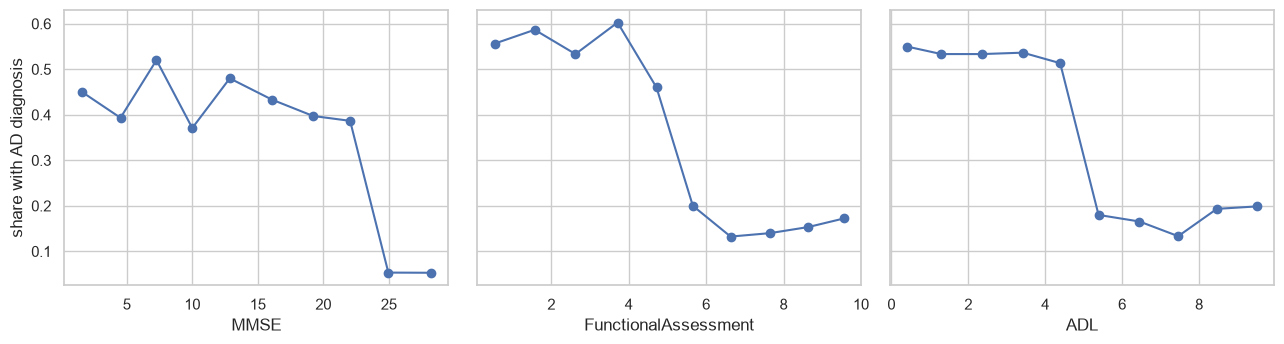

,decile 1,decile 2,decile 3,decile 4,decile 5,decile 6,decile 7,decile 8,decile 9,decile 10
MMSE,0.45,0.39,0.52,0.37,0.48,0.43,0.40,0.39,0.05,0.05
FunctionalAssessment,0.56,0.59,0.53,0.60,0.46,0.20,0.13,0.14,0.15,0.17
ADL,0.55,0.53,0.53,0.54,0.51,0.18,0.17,0.13,0.19,0.20


In [7]:
key = ["MMSE", "FunctionalAssessment", "ADL"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, col in zip(axes, key):
    bins = pd.qcut(X[col], 10)
    rate = y.groupby(bins, observed=True).mean()
    ax.plot([b.mid for b in rate.index], rate.to_numpy(), marker="o")
    ax.set_xlabel(col)
axes[0].set_ylabel("share with AD diagnosis")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_binned_rates.png", dpi=150)
plt.show()
pd.DataFrame({col: y.groupby(pd.qcut(X[col], 10), observed=True).mean().round(2).to_numpy() for col in key},
             index=[f"decile {i}" for i in range(1, 11)]).T

## Train vs. Kaggle test distribution

The 2024 report explained the public/private Kaggle gap by a distribution difference. Compare the
labelled training rows with the unlabelled test rows (standardized mean difference per feature).

In [8]:
smd = ((X_test.mean() - X.mean()) / X.std()).sort_values(key=np.abs, ascending=False)
print(f"largest |standardized mean difference|: {smd.abs().max():.3f} ({smd.index[0]})")
smd.head(5).round(3)

largest |standardized mean difference|: 0.097 (CardiovascularDisease)


CardiovascularDisease    0.097
ADL                      0.090
Diabetes                -0.080
FunctionalAssessment    -0.069
DietQuality              0.063
dtype: float64